# WEEK 1

## Traveling Salesmam 

In [7]:
import numpy as np

def objective_function(x):
    return np.sum(x**2)  # example: minimize sphere function


class PSO:
    def __init__(self, n_particles, dim, bounds, max_iter,
                 w=0.5, c1=1.5, c2=1.5):

        self.n_particles = n_particles
        self.dim = dim
        self.bounds = bounds
        self.max_iter = max_iter

        self.w = w      # inertia
        self.c1 = c1    # personal influence
        self.c2 = c2    # social influence

        # Initialize particles
        self.positions = np.random.uniform(bounds[0], bounds[1],
                                           (n_particles, dim))
        self.velocities = np.random.uniform(-1, 1,
                                            (n_particles, dim))

        # Personal bests
        self.pbest_pos = self.positions.copy()
        self.pbest_val = np.array([objective_function(p) for p in self.positions])

        # Global best
        best_idx = np.argmin(self.pbest_val)
        self.gbest_pos = self.pbest_pos[best_idx].copy()
        self.gbest_val = self.pbest_val[best_idx]

    def optimize(self):
        for _ in range(self.max_iter):

            for i in range(self.n_particles):
                # Evaluate fitness
                fitness = objective_function(self.positions[i])

                # Update personal best
                if fitness < self.pbest_val[i]:
                    self.pbest_val[i] = fitness
                    self.pbest_pos[i] = self.positions[i].copy()

            # Update global best
            best_idx = np.argmin(self.pbest_val)
            self.gbest_pos = self.pbest_pos[best_idx].copy()
            self.gbest_val = self.pbest_val[best_idx]

            # Update velocity and position
            for i in range(self.n_particles):
                r1 = np.random.rand(self.dim)
                r2 = np.random.rand(self.dim)

                # Velocity update (matches your formula)
                self.velocities[i] = (
                    self.w * self.velocities[i] +
                    self.c1 * r1 * (self.pbest_pos[i] - self.positions[i]) +
                    self.c2 * r2 * (self.gbest_pos - self.positions[i])
                )

                # Position update
                self.positions[i] += self.velocities[i]

                # Apply bounds
                self.positions[i] = np.clip(self.positions[i],
                                            self.bounds[0],
                                            self.bounds[1])

        return self.gbest_pos, self.gbest_val


# Example usage
if __name__ == "__main__":
    pso = PSO(
        n_particles=30,
        dim=2,
        bounds=(-10, 10),
        max_iter=100
    )

    best_pos, best_val = pso.optimize()

    print("Best Position:", best_pos)
    print("Best Value:", best_val)

Best Position: [-2.29554032e-13 -6.92608712e-14]
Best Value: 5.7492121948257e-26


# WEEK 2

## Best location for food Delivery Hub

In [6]:
import numpy as np

customers = np.array([
    [2, 3],
    [5, 8],
    [1, 6],
    [7, 2],
    [6, 6]
])

def fitness(position):
    return sum(np.linalg.norm(position - c) for c in customers)

n_particles = 20
dim = 2
max_iter = 100

# bounds (city area)
bounds = (0, 10)

# coefficients
w = 0.5
c1 = 1.5
c2 = 1.5

# initialize particles
positions = np.random.uniform(bounds[0], bounds[1], (n_particles, dim))
velocities = np.random.uniform(-1, 1, (n_particles, dim))

# pbest
pbest_pos = positions.copy()
pbest_val = np.array([fitness(p) for p in positions])

# gbest
gbest_index = np.argmin(pbest_val)
gbest_pos = pbest_pos[gbest_index].copy()

for _ in range(max_iter):

    for i in range(n_particles):
        fp = fitness(positions[i])

        # update pbest
        if fp < pbest_val[i]:
            pbest_val[i] = fp
            pbest_pos[i] = positions[i].copy()

    # update gbest
    gbest_index = np.argmin(pbest_val)
    gbest_pos = pbest_pos[gbest_index].copy()

    # update velocity and position
    for i in range(n_particles):
        r1 = np.random.rand(dim)
        r2 = np.random.rand(dim)

        velocities[i] = (
            w * velocities[i]
            + c1 * r1 * (pbest_pos[i] - positions[i])
            + c2 * r2 * (gbest_pos - positions[i])
        )

        positions[i] = positions[i] + velocities[i]

        # keep inside bounds
        positions[i] = np.clip(positions[i], bounds[0], bounds[1])

print("Optimal Hub Location:", gbest_pos)
print("Minimum Total Distance:", fitness(gbest_pos))

Optimal Hub Location: [4.51290611 5.42610527]
Minimum Total Distance: 15.499646744527489


# WEEK 3

## Employee Job scheduling

In [1]:
import random

N = 6
POP = 10
GEN = 20

def fitness(x):
    return sum(x)   # minimize total shift cost

pop = [[random.randint(1, 10) for _ in range(N)]
       for _ in range(POP)]

for _ in range(GEN):
    pop.sort(key=fitness)
    parents = pop[:2]

    new_pop = parents[:]

    while len(new_pop) < POP:
        p1, p2 = random.sample(parents, 2)
        cut = random.randint(1, N-1)

        child = p1[:cut] + p2[cut:]

        if random.random() < 0.1:
            i = random.randrange(N)
            child[i] = random.randint(1, 10)

        new_pop.append(child)

    pop = new_pop

best = min(pop, key=fitness)

print("Best Schedule:", best)
print("Minimum Cost:", fitness(best))

Best Schedule: [2, 1, 5, 2, 1, 1]
Minimum Cost: 12


# WEEK 4

# Ant Colony Optimization (ACO) for the Traveling Salesman Problem

Best Tour: 2 -> 0 -> 1 -> 4 -> 3 -> 2
Minimum Distance: 20.3


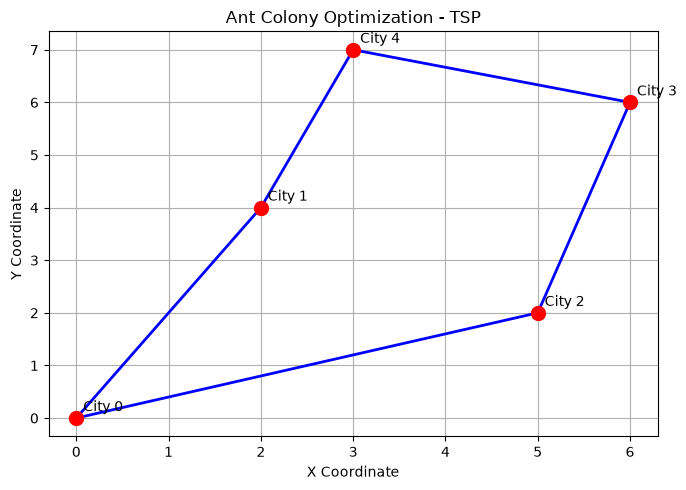

In [3]:

import random
import matplotlib.pyplot as plt

# Coordinates of 5 cities
cities = [(0, 0), (2, 4), (5, 2), (6, 6), (3, 7)]
n = len(cities)

# Create distance matrix from city coordinates
distance = [[0.0] * n for _ in range(n)]

for i in range(n):
    for j in range(n):
        if i != j:
            x1, y1 = cities[i]
            x2, y2 = cities[j]
            distance[i][j] = (
                (x2 - x1)**2 + (y2 - y1)**2
            )**0.5

# ACO algorithm
def ant_colony_tsp(distance, ants=10, iterations=100,
                   alpha=1, beta=2, rho=0.5, Q=100):

    n = len(distance)
    pheromone = [[1.0] * n for _ in range(n)]

    best_tour = None
    best_distance = float("inf")

    for _ in range(iterations):
        all_tours = []

        for _ in range(ants):
            start = random.randrange(n)
            tour = [start]
            unvisited = list(range(n))
            unvisited.remove(start)

            while unvisited:
                current = tour[-1]
                weights = []

                for city in unvisited:
                    tau = pheromone[current][city] ** alpha
                    eta = (1 / distance[current][city]) ** beta
                    weights.append(tau * eta)

                next_city = random.choices(
                    unvisited, weights=weights, k=1
                )[0]

                tour.append(next_city)
                unvisited.remove(next_city)

            tour.append(start)

            length = sum(
                distance[tour[i]][tour[i + 1]]
                for i in range(n)
            )

            all_tours.append((tour, length))

            if length < best_distance:
                best_distance = length
                best_tour = tour[:]

        # Evaporate pheromones
        for i in range(n):
            for j in range(n):
                pheromone[i][j] *= (1 - rho)

        # Deposit pheromones
        for tour, length in all_tours:
            deposit = Q / length

            for i in range(n):
                a, b = tour[i], tour[i + 1]
                pheromone[a][b] += deposit
                pheromone[b][a] += deposit

    return best_tour, best_distance


# Run ACO
random.seed(42)
tour, length = ant_colony_tsp(distance)

print("Best Tour:", " -> ".join(map(str, tour)))
print("Minimum Distance:", round(length, 2))

# Plot cities and best tour
x = [city[0] for city in cities]
y = [city[1] for city in cities]

plt.figure(figsize=(7, 5))
plt.scatter(x, y, color="red", s=100, zorder=3)

for i, (cx, cy) in enumerate(cities):
    plt.annotate(
        f"City {i}", (cx, cy),
        xytext=(5, 5), textcoords="offset points"
    )

# Draw the best route
for i in range(len(tour) - 1):
    a, b = tour[i], tour[i + 1]
    plt.plot(
        [cities[a][0], cities[b][0]],
        [cities[a][1], cities[b][1]],
        "b-", linewidth=2
    )

plt.title("Ant Colony Optimization - TSP")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid(True)
plt.tight_layout()
plt.show()
